# Next-day AQI prediction for five Indian cities

Samuel Flores and Santiago Becerra — ETL G51, final delivery.

This notebook extends the earlier EDA and validated PostgreSQL warehouse. It does not replace the three-source ETL. The operational question is: **given the observations available through a local calendar day, can we estimate the next day's AQI?** The historical stream is a replay for an academic demonstration, not live environmental monitoring.

Run the Airflow ETL first. The training module reads `india_dw.air_quality_enriched`, the same dimensional view used by the static report and Kafka producer. Configure `INDIA_DATABASE_URL` in the environment; do not paste credentials into this notebook.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
ROOT = Path(os.environ.get('INDIA_PROJECT_ROOT', Path.cwd())).resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'final_ml.py').exists(), 'Set INDIA_PROJECT_ROOT to the project directory'
sys.path.insert(0, str(ROOT / 'src'))
from final_ml import FEATURE_COLUMNS, read_warehouse, build_features, training_labels, temporal_split, train
DATABASE_URL = os.environ['INDIA_DATABASE_URL']
ARTIFACTS = ROOT / 'artifacts'


## Source and forecasting features

The target is numeric AQI at day `t+1`. `aqi_lag1` is AQI at origin day `t`; it is not the target. The seven-day average includes only `t-6` through `t`. Pollutants and ERA5 weather also belong to `t`. Calendar features describe the known forecast date. City coordinates contribute upstream by locating the weather requests, while `city_name` encodes location for the model.

Rows with incomplete consecutive seven-day histories are excluded. Missing or non-finite source values and duplicate keys fail explicitly. We do not impute data to hide an ETL problem. No target-day pollutant, AQI category, future weather, centered rolling average or target value enters the feature vector.

In [2]:
source = read_warehouse(DATABASE_URL)
features = build_features(source)
labeled = training_labels(source)
display(pd.DataFrame({'rows': [len(source), len(features), len(labeled)]}, index=['warehouse', 'inference rows', 'labeled rows']))
display(labeled[['city_name', 'origin_date', 'target_date'] + FEATURE_COLUMNS[1:] + ['target_aqi']].head())
assert 'target_aqi' not in FEATURE_COLUMNS
assert 'aqi_bucket' not in FEATURE_COLUMNS


,rows
warehouse,18265
inference rows,18235
labeled rows,18230


,city_name,origin_date,target_date,month,day_of_week,aqi_lag1,aqi_mean7,pm25_lag1,pm10_lag1,no2_lag1,temperature_lag1,precipitation_lag1,wind_lag1,target_aqi
0,Bangalore,2015-01-07,2015-01-08,1,3,302.5,301.071429,122.9,583.2,146.3,22.1,0.0,2.38,192.0
1,Chennai,2015-01-07,2015-01-08,1,3,475.4,320.814286,325.4,129.0,57.5,25.3,0.1,3.35,278.6
2,Delhi,2015-01-07,2015-01-08,1,3,432.3,348.771429,282.3,420.9,134.7,11.9,0.0,3.14,465.2
3,Kolkata,2015-01-07,2015-01-08,1,3,301.3,332.742857,121.4,120.8,10.4,17.4,0.0,2.46,458.5
4,Mumbai,2015-01-07,2015-01-08,1,3,169.2,319.257143,485.1,549.4,40.5,23.4,0.0,4.30,252.5


## Evaluation design

All cities use the same target-date boundaries: training through 2021, validation during 2022 and final test during 2023–2024. We compare Ridge regression with a small Random Forest and select the candidate with the lowest validation MAE. The chosen architecture is then fitted again on training plus validation data; the test period never chooses the model or fits preprocessing.

The model pipeline contains a numeric StandardScaler, OneHotEncoder for city, and the regressor. The pipeline is serialized once for Kafka inference. Mean-AQI and previous-day persistence baselines provide meaningful references. A model that fails to beat a baseline is reported as such.

Airflow already trains and saves the model during the final DAG. By default, this notebook reads those existing evaluation artifacts without changing the model used by the running Kafka consumer. Set `RETRAIN = True` explicitly to reproduce training from the current validated warehouse, or run the training cell when no saved metadata exists. Retraining replaces the artifacts; restart the consumer afterwards to use the newly fitted model.

In [3]:
training, validation, test = temporal_split(labeled)
display(pd.DataFrame([{'partition': name, 'rows': len(part), 'first_target': part.target_date.min(), 'last_target': part.target_date.max()} for name, part in [('training', training), ('validation', validation), ('test', test)]]))
assert training.target_date.max() < validation.target_date.min() < test.target_date.min()
# Read the DAG artifacts by default; opt in explicitly to replace them.
RETRAIN = False
metadata_path = ARTIFACTS / 'metadata.json'
if RETRAIN or not metadata_path.exists():
    metadata = train(DATABASE_URL, ARTIFACTS)
else:
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
display(pd.DataFrame(metadata['metrics']['validation']).T.round(3))
display(pd.DataFrame(metadata['metrics']['test']).T.round(3))
print('Selected:', metadata['model_name'], '| version:', metadata['model_version'])


,partition,rows,first_target,last_target
0,training,12750,2015-01-08,2021-12-31
1,validation,1825,2022-01-01,2022-12-31
2,test,3655,2023-01-01,2024-12-31


,mae,rmse,r2
ridge,96.849,112.288,-0.003
random_forest,97.031,112.455,-0.006
mean_baseline,96.709,112.135,-0.000
persistence_baseline,128.894,158.105,-0.988


,mae,rmse,r2
selected_model,98.773,114.173,-0.002
mean_baseline,98.680,114.093,-0.000
persistence_baseline,132.874,162.551,-1.030


Selected: ridge | version: 90b6dd4d28661a89


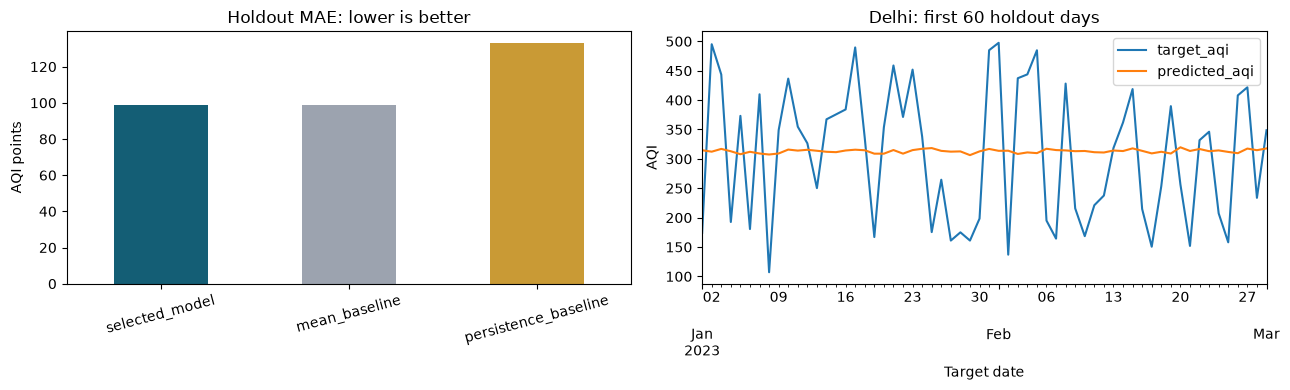

,mae,rmse,r2
Bangalore,95.521,110.788,-0.000
Chennai,103.304,118.654,-0.001
Delhi,97.417,112.929,-0.002
Kolkata,101.771,116.114,-0.004
Mumbai,95.853,112.201,-0.002


In [4]:
import matplotlib.pyplot as plt
results = pd.read_csv(ARTIFACTS / 'test_predictions.csv', parse_dates=['target_date'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
scores = pd.DataFrame(metadata['metrics']['test']).T
scores['mae'].plot.bar(ax=axes[0], color=['#145e75', '#9ca3af', '#c99a35'])
axes[0].set(title='Holdout MAE: lower is better', ylabel='AQI points', xlabel='')
axes[0].tick_params(axis='x', rotation=15)
city = 'Delhi'
sample = results[results.city_name.eq(city)].sort_values('target_date').head(60)
sample.plot(x='target_date', y=['target_aqi', 'predicted_aqi'], ax=axes[1])
axes[1].set(title=f'{city}: first 60 holdout days', ylabel='AQI', xlabel='Target date')
fig.tight_layout()
plt.show()
display(pd.DataFrame(metadata['by_city_test']).T.round(3))


In [5]:
from IPython.display import Markdown, display
m = metadata['metrics']['test']
status = 'improves on' if metadata['beats_mean_baseline_on_test'] else 'does not improve on'
display(Markdown(f"The selected **{metadata['model_name']}** has test MAE **{m['selected_model']['mae']:.2f} AQI points** and R² **{m['selected_model']['r2']:.3f}**. It **{status}** the training-mean baseline (MAE {m['mean_baseline']['mae']:.2f}). Previous-day persistence has MAE {m['persistence_baseline']['mae']:.2f}. These scores describe held-out historical data and do not establish operational forecasting reliability."))
display(Markdown('### Limitations\n' + '\n'.join('- ' + item for item in metadata['limitations'])))


The selected **ridge** has test MAE **98.77 AQI points** and R² **-0.002**. It **does not improve on** the training-mean baseline (MAE 98.68). Previous-day persistence has MAE 132.87. These scores describe held-out historical data and do not establish operational forecasting reliability.

### Limitations
- Academic next-day prediction experiment, not a validated public warning system.
- The original Kaggle source does not establish measurement units or station provenance for every pollutant.
- ERA5 weather is historical reanalysis; only weather from the origin day enters a forecast event.
- Daily timestamps are assumed to represent local days in India, consistent with the earlier ETL.
- Weak associations and weak temporal persistence can limit accuracy; baseline comparisons are reported even when superior.
- The stream replays historical validated observations; event creation time is distinct from the historical observation date.
- The fitted model uses target dates through 2022 only; demo forecasts for 2023-24 are chronologically out of training.

## Reuse during Kafka inference

The producer calls the same `build_features` function and publishes only the documented feature fields plus identifiers, observation date, forecast date, source run and event creation time. Ground-truth `target_aqi` stays offline. The consumer loads `artifacts/model.joblib` once, applies `predict` to each valid feature record, and stores its prediction with the model version and Kafka position. The dashboard reads these consumer outputs. It does not retrain or replace Kafka with repeated warehouse queries.

Both valid forecasts and weak performance are useful evidence: the architecture demonstrates reproducible inference, while the evaluation establishes whether this dataset supports a useful predictor.